# Avance 5.8. Modelo final

Equipo 8 · Cardio AI (Artificial Intelligence; inteligencia artificial)

- Clara Janet Rivera Medina · A01173512
- José Emiliano Luna López · A01551757
- Andre Nicolai Gutierrez Bautista · A01793606

Buscamos apoyar al cardiólogo en dos tareas: priorizar ECG (electrocardiogramas) para revisión y mostrar qué partes
influyen en una alerta. Comparamos modelos individuales y cinco ensambles, estudiamos tres modelos preentrenados
y usamos un cohort de 25,000 ECG sin preferencia por edad.

El resultado predice anotaciones del ECG, no un diagnóstico confirmado. Los datos de
hospitales sirven para desarrollar el modelo; todavía falta validarlo en estudiantes de Italia.

## 1. Datos, ejecución y comparación justa

La etiqueta positiva corresponde al proxy de alteraciones MI (Myocardial Infarction; infarto de miocardio),
STTC (ST-T Changes; cambios del segmento ST y de la onda T), CD (Conduction Disturbance;
trastornos de conducción) o HYP (Hypertrophy; hipertrofia) definido por
el proyecto. Conservamos las definiciones admitidas por fuente y no cambiamos las etiquetas
después de ver los resultados. Los 25,000 ECG tienen evidencia de anotación humana y controles
de calidad; esta selección recuperada no es una copia del antiguo cohort de preentrenamiento.

Los hiperparámetros se eligen con tres particiones de entrenamiento, manteniendo juntos a
los pacientes conocidos. La imputación y el escalado se ajustan dentro de cada partición.
Cuando una fuente no identifica al paciente, solo podemos separar registros.

PTB-XL (base asociada a la Physikalisch-Technische Bundesanstalt, instituto alemán de metrología),
en su pliegue 9, y SPH (Shandong Provincial Hospital; Hospital Provincial de Shandong)
son evaluación de desarrollo reutilizada. [Fuente de SPH](https://pmc.ncbi.nlm.nih.gov/articles/PMC9174207/). Los normales de calibración
de cada hospital fijan su umbral. No evaluamos el pliegue 10, los grupos reservados de Challenge
ni la prueba de EchoNext. La métrica principal es AUROC (Area Under the Receiver Operating Characteristic Curve;
área bajo la curva ROC, Receiver Operating Characteristic o característica operativa del receptor); también medimos sensibilidad,
especificidad, precisión promedio y tiempo. AUROC no significa porcentaje de diagnósticos correctos.

Usamos AP (Average Precision; precisión promedio) para resumir la curva de precisión–recall.
La referencia histórica la llama AUPRC (Area Under the Precision–Recall Curve; área bajo
esa curva), aunque su código calcula AP. VC (validación cruzada) identifica los resultados
internos de entrenamiento e IC (intervalo de confianza) expresa la incertidumbre.
En las matrices: VP (verdaderos positivos), FN (falsos negativos), FP (falsos positivos)
y VN (verdaderos negativos); TP (True Positives) y TN (True Negatives) son los nombres
en inglés que conservan algunas tablas. VPP (valor predictivo positivo) es la proporción
de alertas que corresponden a positivos de referencia.

Esta libreta requiere los datos y caches locales documentados; GitHub conserva código y
resultados agregados, no ECG ni pesos. El módulo Python ejecuta el trabajo y deja aquí las salidas.

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "2"
import sys
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "ecg_experiment").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from ecg_experiment import avance5 as a5
from ecg_experiment.avance5_cache import delivery_run
from ecg_experiment.files import write_json_atomic
MODEL_LABELS = {"xECG + logística": "xECG con regresión logística"}
START = time.perf_counter()
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 65)
plt.style.use("seaborn-v0_8-whitegrid")
a5.OUT.mkdir(parents=True, exist_ok=True)
a5.REPORT.mkdir(parents=True, exist_ok=True)
replay = a5.replay_existing()
display(Markdown(f"Verificación previa: la matriz histórica del cohort general se reprodujo "
                 f"exactamente: {replay['metrics']['tp']:,} VP, {replay['metrics']['fn']:,} FN, "
                 f"{replay['metrics']['fp']:,} FP y {replay['metrics']['tn']:,} VN."))

Verificación previa: la matriz histórica del cohort general se reprodujo exactamente: 2,774 VP, 810 FN, 358 FP y 6,492 VN.

In [2]:
rows, raw, vectors = a5.training_data()
population = rows.groupby("source").agg(ECG=("record_id", "size"),
    positivos=("target", lambda values: (values == "1").sum()))
population["normales"] = population.ECG - population.positivos
display(population.rename(index={"cpsc_2018": "CPSC (China Physiological Signal Challenge), 2018",
    "cpsc_2018_extra": "CPSC, registros adicionales"}))
display(Markdown(f"Total: {len(rows):,} ECG, {raw.shape[1]} medidas físicas y "
                 f"{vectors.shape[1]} variables aprendidas por xECG. "
                 f"Hay {(rows.patient_id == '').sum():,} registros sin identidad de paciente."))

,ECG,positivos,normales
source,,,
chapman_shaoxing,3050,2231,819
"CPSC (China Physiological Signal Challenge), 2018",655,501,154
"CPSC, registros adicionales",541,541,0
georgia,3974,3173,801
ningbo,9952,7371,2581
ptbxl,6828,3790,3038


Total: 25,000 ECG, 130 medidas físicas y 1024 variables aprendidas por xECG. Hay 18,172 registros sin identidad de paciente.

## 2. Tres modelos preentrenados para interpretar señales

Usamos pesos publicados. El procesamiento tiene dos pasos: el codificador extrae características
de la señal y una regresión logística, un clasificador lineal, las convierte en una puntuación
de anormalidad. En esta comparación entrenamos ese clasificador final y mantenemos fijo el
codificador. Por eso llamamos a la configuración xECG con regresión logística: describe
las dos etapas de un mismo sistema de clasificación.

xECG es el nombre publicado de un modelo para electrocardiogramas basado en memoria recurrente extendida.

| Modelo | Idea principal | Fuente |
|---|---|---|
| ECG-JEPA (Joint-Embedding Predictive Architecture; arquitectura predictiva de representaciones conjuntas) | Predice representaciones de partes ocultas; aprende relaciones entre derivaciones. | [Kim, 2024; versión 2026](https://arxiv.org/abs/2410.08559) |
| ECG-CPC (Contrastive Predictive Coding; codificación predictiva contrastiva), con S4 (Structured State Space Sequence Model; modelo secuencial de espacio de estados estructurado) | Aprende a anticipar representaciones futuras con un objetivo contrastivo y bloques de espacio de estados. | [Al-Masud et al., 2026](https://arxiv.org/abs/2509.25095) |
| xECG | Combina preentrenamiento autosupervisado con bloques xLSTM (Extended Long Short-Term Memory; memoria extendida de corto y largo plazo) para representar el ECG completo. | [Lunelli et al., 2026](https://doi.org/10.1038/s41746-026-03196-y) |

Para compararlos usamos los mismos ECG de PTB-XL: entrenamiento en pliegues 1–7,
calibración en el 8 y evaluación en el 9, con la misma cabeza logística (`C=0.01`).
No son tres modelos preentrenados con nuestros 25,000 ECG: sus autores usaron poblaciones
y presupuestos diferentes. Nuestro CPC es el S4 publicado, no el prototipo local CNN (Convolutional Neural Network; red neuronal convolucional)
con GRU (Gated Recurrent Unit; unidad recurrente con compuertas).

In [3]:
pretrained = a5.pretrained_comparison()
display(pretrained[["modelo", "auroc", "average_precision", "sensitivity", "specificity",
                    "ajuste_cabeza_s", "dimension"]].round(4))
best_pretrained = pretrained.iloc[0]
display(Markdown(f"En esta comparación, {best_pretrained.modelo} obtiene el mayor AUROC "
    f"({best_pretrained.auroc:.4f}). La ventaja describe esta tarea y este modo de evaluación; "
    "no establece que una arquitectura sea mejor para todos los problemas de ECG. "
    "El tiempo mostrado corresponde a ajustar la cabeza; no incluye el preentrenamiento publicado."))

,modelo,auroc,average_precision,sensitivity,specificity,ajuste_cabeza_s,dimension
2,xECG,0.9431,0.9607,0.7411,0.9628,1.1404,1024
0,ECG-JEPA,0.9410,0.9589,0.7394,0.9540,1.8489,768
1,ECG-CPC S4,0.9188,0.9455,0.6867,0.9617,0.2482,512


En esta comparación, xECG obtiene el mayor AUROC (0.9431). La ventaja describe esta tarea y este modo de evaluación; no establece que una arquitectura sea mejor para todos los problemas de ECG. El tiempo mostrado corresponde a ajustar la cabeza; no incluye el preentrenamiento publicado.

## 3. Modelos individuales y ensambles

Conservamos SVM (Support Vector Machine; máquina de vectores de soporte)
y MLP (Multilayer Perceptron; perceptrón multicapa), las dos alternativas fuertes del Avance 4, y las adaptamos a las
130 medidas del cohort multisede. Su entrada ahora es distinta de las 111 características
seleccionadas del avance anterior; el efecto no puede atribuirse solo al algoritmo.

| Modelo | Estrategia | Cómo se construye |
|---|---|---|
| Logística, SVM y MLP | Individual | Aprenden de las medidas físicas. |
| xECG con regresión logística | Individual transferido | xECG extrae características y la regresión logística calcula la puntuación final. |
| Random forest | Ensamble homogéneo | Agrega 160 árboles entrenados con muestras distintas. |
| Histogram boosting | Ensamble homogéneo | Añade árboles que corrigen errores anteriores. |
| Voto SVM + MLP | Ensamble heterogéneo | Promedia sus puntuaciones; la SVM usa el sigmoide del margen. |
| Stacking SVM + MLP | Ensamble heterogéneo | Una logística combina predicciones fuera de muestra de ambos. |
| Mezcla boosting + xECG | Ensamble heterogéneo | Promedio fijo 50:50 de medidas físicas y representación aprendida. |

Ajustamos dos opciones de `max_features` del bosque, tres tamaños de árbol del boosting y
tres valores de regularización de la cabeza xECG. Cada opción se mide en tres particiones
de entrenamiento. Para SVM y MLP reutilizamos recetas del Avance 4; la MLP usa 64 neuronas.

Elegimos el modelo con mayor AUROC fuera de muestra en entrenamiento. El stacking se
evalúa después en los hospitales, pero su diagnóstico interno no participa en la selección:
elegirlo allí exigiría una validación anidada adicional. Ningún dato SPH ajusta un clasificador.

In [4]:
run = delivery_run()
display(run["fitted"]["search"].replace({"modelo": MODEL_LABELS}).round(4))

Ajustes completados reutilizados; métricas, umbrales, roles y hashes verificados. No se cargaron modelos serializados.


,modelo,parametros,AUROC_VC,desv_VC,busqueda_s
0,Random forest,"{""randomforestclassifier__max_features"": ""sqrt""}",0.9735,0.0024,241.0236
1,Random forest,"{""randomforestclassifier__max_features"": 0.5}",0.9715,0.0024,241.0236
2,Histogram boosting,"{""learning_rate"": 0.08, ""max_leaf_nodes"": 7}",0.9740,0.0020,5.3458
3,Histogram boosting,"{""learning_rate"": 0.08, ""max_leaf_nodes"": 15}",0.9764,0.0016,5.3458
4,Histogram boosting,"{""learning_rate"": 0.08, ""max_leaf_nodes"": 31}",0.9773,0.0020,5.3458
5,xECG con regresión logística,"{""logisticregression__C"": 0.001}",0.9738,0.0012,4.2599
6,xECG con regresión logística,"{""logisticregression__C"": 0.01}",0.9765,0.0009,4.2599
7,xECG con regresión logística,"{""logisticregression__C"": 0.1}",0.9766,0.0004,4.2599


## 4. Resultados comparables y selección

Las tablas siguientes incluyen a los modelos individuales y los cinco ensambles, ordenados
por AUROC en cada hospital. Los tiempos de ajuste final corresponden a los 25,000 ECG;
OOF (Out of Fold; fuera del pliegue de entrenamiento), en la columna `OOF_s`, muestra por separado el costo de generar predicciones de entrenamiento fuera de muestra.
Para stacking, el ajuste incorpora ese paso necesario para construir la cabeza combinadora.
Los ensambles reutilizan componentes, pero el tiempo reporta el costo de construir su receta.

In [5]:
table = run["table"].replace({"modelo": MODEL_LABELS})
show_columns = ["modelo", "auroc", "average_precision", "sensitivity", "specificity",
                "precision", "ajuste_final_s", "OOF_s"]
for site in ("ptb", "sph"):
    display(Markdown(f"{site.upper()} · evaluación de desarrollo"))
    display(table.query("sitio == @site")[show_columns].round(4))
selected = run["summary"]["selected"]
selected_name = run["summary"]["selected_label"]
final = table.query("sitio == 'sph' and id == @selected").iloc[0]
interval = a5.comparison_interval(run)
display(Markdown(f"La regla fijada en entrenamiento elige {selected_name}. En SPH obtiene "
    f"AUROC {final.auroc:.4f}, sensibilidad {final.sensitivity:.1%} y especificidad "
    f"{final.specificity:.1%}. Su diferencia de AUROC frente a xECG con regresión logística es "
    f"{interval['difference']:+.4f}, IC 95% [{interval['ci_low']:+.4f}, {interval['ci_high']:+.4f}], "
    "con 2,000 remuestreos de pacientes completos. Es una comparación de desarrollo, "
    "condicional a estos modelos y a esta calibración."))
write_json_atomic(a5.REPORT / "intervalo_vs_xecg.json", interval)

PTB · evaluación de desarrollo

,modelo,auroc,average_precision,sensitivity,specificity,precision,ajuste_final_s,OOF_s
0,Mezcla boosting + xECG,0.9259,0.9463,0.6851,0.9628,0.9613,3.7229,6.0068
1,xECG con regresión logística,0.9203,0.9423,0.6502,0.9694,0.9662,2.1103,3.1054
2,Histogram boosting,0.9192,0.9404,0.6307,0.9606,0.9557,1.6126,2.9014
3,Stacking SVM + MLP,0.9185,0.9410,0.6469,0.9639,0.9602,38.5023,23.3565
4,Voto SVM + MLP,0.9185,0.9410,0.6420,0.9650,0.9611,15.1398,23.3565
5,SVM · medidas,0.9180,0.9409,0.6485,0.9628,0.9592,6.4059,10.5178
6,MLP · medidas,0.9176,0.9409,0.6518,0.9606,0.9571,8.7339,12.8387
7,Random forest,0.9154,0.9371,0.6469,0.9562,0.9522,27.9042,33.9879
8,Logística · medidas,0.8933,0.9248,0.5657,0.9672,0.9587,0.2775,0.6472


SPH · evaluación de desarrollo

,modelo,auroc,average_precision,sensitivity,specificity,precision,ajuste_final_s,OOF_s
9,Mezcla boosting + xECG,0.9374,0.9183,0.7740,0.9507,0.8914,3.7229,6.0068
10,xECG con regresión logística,0.9321,0.9119,0.7609,0.9504,0.8891,2.1103,3.1054
11,Histogram boosting,0.9272,0.8956,0.7472,0.9448,0.8763,1.6126,2.9014
12,Random forest,0.9250,0.8978,0.7257,0.9504,0.8844,27.9042,33.9879
13,Stacking SVM + MLP,0.9145,0.8876,0.7076,0.9474,0.8757,38.5023,23.3565
14,Voto SVM + MLP,0.9144,0.8875,0.7084,0.9477,0.8764,15.1398,23.3565
15,SVM · medidas,0.9133,0.8856,0.7020,0.9482,0.8763,6.4059,10.5178
16,MLP · medidas,0.9126,0.8747,0.7028,0.9486,0.8774,8.7339,12.8387
17,Logística · medidas,0.8833,0.8337,0.5988,0.9574,0.8802,0.2775,0.6472


La regla fijada en entrenamiento elige Mezcla boosting + xECG. En SPH obtiene AUROC 0.9374, sensibilidad 77.4% y especificidad 95.1%. Su diferencia de AUROC frente a xECG con regresión logística es +0.0052, IC 95% [+0.0034, +0.0072], con 2,000 remuestreos de pacientes completos. Es una comparación de desarrollo, condicional a estos modelos y a esta calibración.

Como referencia histórica, mostramos también el modelo individual elegido en el Avance 4.
Se entrenó con otra entrada y otra cantidad de ECG. Sus números no se mezclan con la tabla
multisede para evitar presentar dos experimentos diferentes como una comparación controlada.

In [6]:
old = a5.json_read(ROOT / "outputs/avance4_modelos/modelo_final_metricas.json")
display(pd.DataFrame([{ "modelo": old["modelo_final"] + " · Avance 4, 111 características",
                       "evaluacion": "PTB pliegue 9", **old["validacion"] }]).round(4))

,modelo,evaluacion,AUROC,sens_con_esp_90,esp_con_sens_95,AUPRC
0,"Red neuronal (MLP) · Avance 4, 111 características",PTB pliegue 9,0.9395,0.8279,0.6521,0.9579


## 5. Cuatro gráficos para entender el modelo elegido

La ROC muestra separación entre clases; la curva precisión–recall muestra cuántas alertas
corresponden a positivos de referencia. La matriz traduce las tasas a conteos. El estudio de
umbrales enseña el intercambio entre positivos recuperados y falsas alertas.

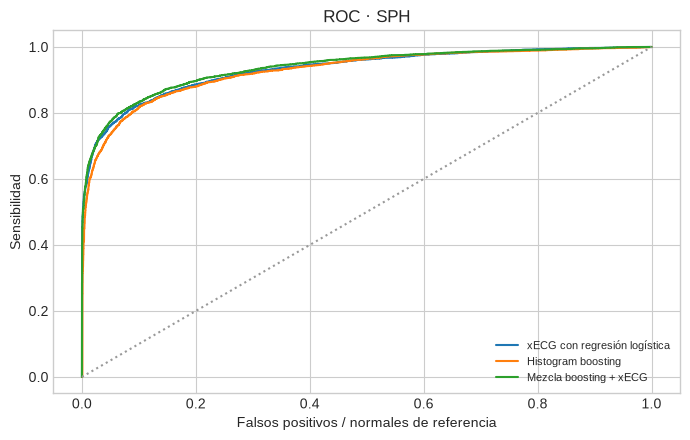

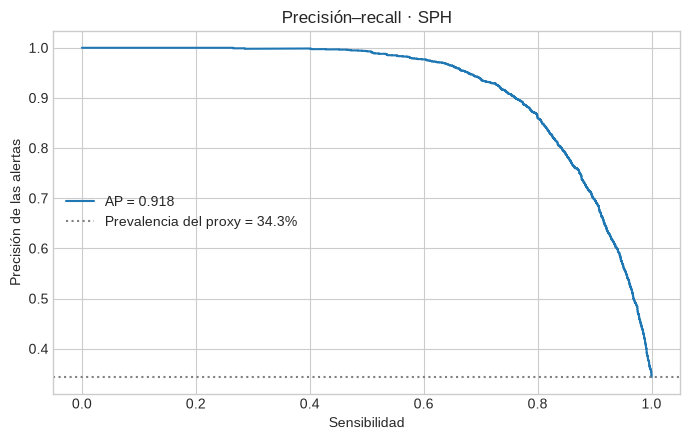

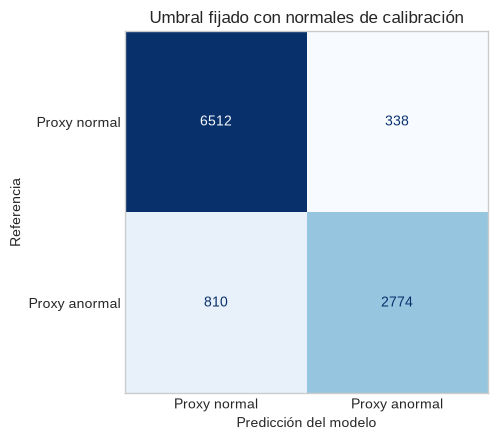

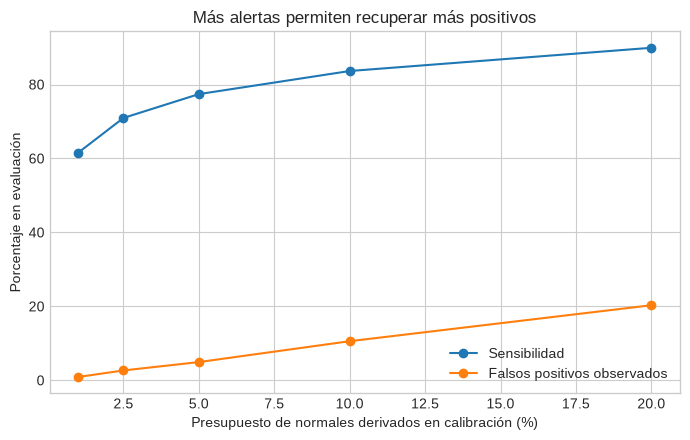

ROC: AUROC 0.9374; resume el ordenamiento a través de todos los umbrales, no garantiza sensibilidad alta en el punto que elija el médico.

Precisión–recall: precisión promedio 0.9183, con prevalencia del proxy 34.3% en SPH. Esa precisión no se traslada a estudiantes con una prevalencia mucho menor.

Matriz: 2,774 verdaderos positivos, 810 falsos negativos, 338 falsos positivos y 6,512 verdaderos negativos. Se enviarían a revisión 3,112 de 10,434 ECG.

Umbrales: cada punto se fija solo con normales de calibración. Subir la carga aceptada puede recuperar positivos, a costa de revisar más normales; la tabla siguiente cuantifica ese costo.

In [7]:
a5.NAMES["xecg"] = "xECG con regresión logística"
figures = a5.plot_final(run)
for figure_number in plt.get_fignums():
    figure = plt.figure(figure_number)
    if not any(axis.images for axis in figure.axes):
        continue
    for axis in figure.axes:
        axis.grid(False)
    figure.savefig(figures[2], dpi=160, bbox_inches="tight")
plt.show()
display(Markdown(f"ROC: AUROC {final.auroc:.4f}; resume el ordenamiento a través de todos los umbrales, "
    "no garantiza sensibilidad alta en el punto que elija el médico.\n\n"
    f"Precisión–recall: precisión promedio {final.average_precision:.4f}, con prevalencia del proxy "
    f"{final.positives / final.ecgs:.1%} en SPH. Esa precisión no se traslada a estudiantes con "
    "una prevalencia mucho menor.\n\n"
    f"Matriz: {int(final.tp):,} verdaderos positivos, {int(final.fn):,} falsos negativos, "
    f"{int(final.fp):,} falsos positivos y {int(final.tn):,} verdaderos negativos. "
    f"Se enviarían a revisión {int(final.tp + final.fp):,} de {int(final.ecgs):,} ECG.\n\n"
    "Umbrales: cada punto se fija solo con normales de calibración. Subir la carga aceptada "
    "puede recuperar positivos, a costa de revisar más normales; la tabla siguiente cuantifica ese costo."))

## 6. Un umbral que el médico pueda entender

El punto de referencia permite derivar hasta el 5% de los normales de calibración.
Eso no equivale al 5% de todas las personas ni garantiza un 5% en un hospital nuevo.
Usamos siempre puntuación > umbral; los empates no se derivan.

La página web permite explorar los conteos al mover un deslizador. Su punto fijo de
calibración permanece visible para comparar. El deslizador es una exploración de datos ya
evaluados; un umbral de uso real debe acordarse y calibrarse con el servicio local.

La captura muestra una vista de solo lectura del prototipo con su modelo de referencia original, entrenado solo con PTB-XL; sus conteos corresponden a ese modelo.

,normal_budget,threshold,tp,fn,fp,tn,sensitivity,specificity,referral_fraction
0,0.010,0.9128,2206,1378,62,6788,0.6155,0.9909,0.2174
1,0.025,0.8057,2543,1041,183,6667,0.7095,0.9733,0.2613
2,0.050,0.6797,2774,810,338,6512,0.7740,0.9507,0.2983
3,0.100,0.4902,2998,586,725,6125,0.8365,0.8942,0.3568
4,0.200,0.3033,3223,361,1391,5459,0.8993,0.7969,0.4422


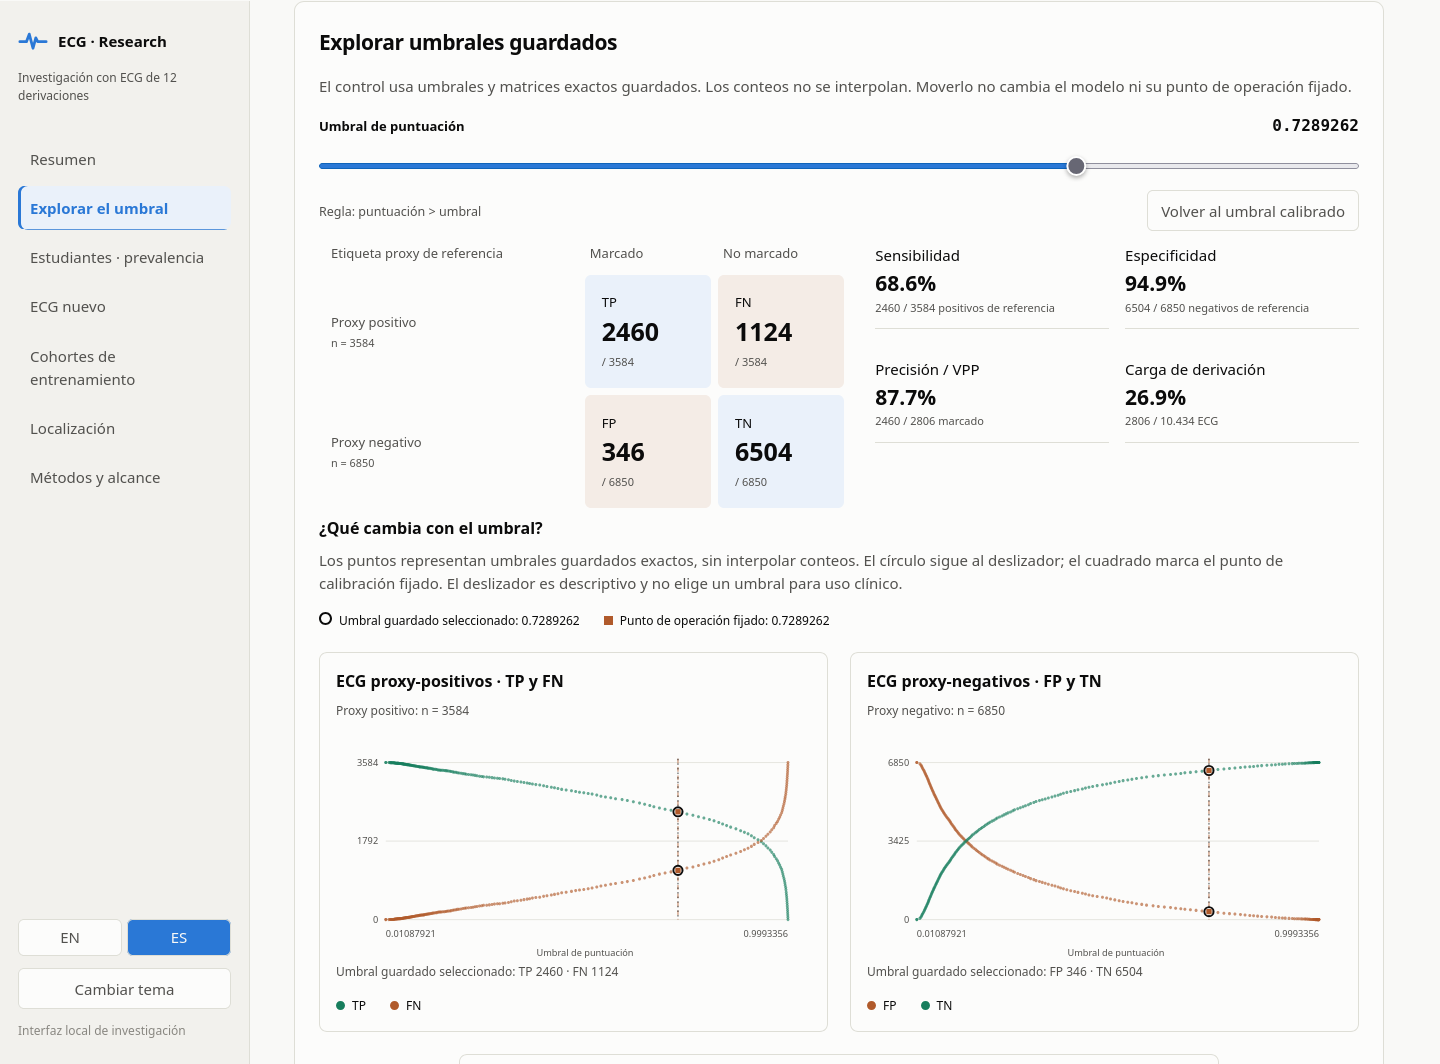

Explorador de umbrales de la aplicación: la captura muestra conteos de revisión, no el apartado de localización.

Al pasar del presupuesto de 1% al 20%, se recuperan 1,017 positivos adicionales y aparecen 1,329 falsas alertas adicionales en este conjunto. La decisión depende de la capacidad de revisión y de las consecuencias de cada error.

In [8]:
budgets = a5.threshold_budgets(run)
display(budgets[["normal_budget", "threshold", "tp", "fn", "fp", "tn", "sensitivity",
                 "specificity", "referral_fraction"]].round(4))
screenshot = ROOT / "docs/figures/avance5-ui/thresholds.png"
if screenshot.is_file():
    display(Image(filename=str(screenshot), width=1000))
display(Markdown("Explorador de umbrales de la aplicación: la captura muestra conteos de revisión, "
                 "no el apartado de localización."))
budgets.to_csv(a5.REPORT / "presupuestos_derivacion.csv", index=False)
low, high = budgets.iloc[0], budgets.iloc[-1]
display(Markdown(f"Al pasar del presupuesto de 1% al 20%, se recuperan "
    f"{int(high.tp - low.tp):,} positivos adicionales y aparecen "
    f"{int(high.fp - low.fp):,} falsas alertas adicionales en este conjunto. "
    "La decisión depende de la capacidad de revisión y de las consecuencias de cada error."))

## 7. Por qué conservar la diversidad de edades

Construimos un grupo estricto de 18–25 años y un control de igual tamaño, ambos con 770 ECG
y la misma composición por fuente, evidencia de anotación y clase. Con la mezcla fija de
boosting y xECG, la sensibilidad SPH fue 70.40% frente a 69.92%: diferencia de 0.47 puntos
porcentuales, IC 95% [−0.72, +1.64]. No alcanzó la mejora mínima de dos puntos fijada antes.

También comparamos dos selecciones de 25,000 ECG: una priorizada por edad y otra general.
La primera sigue siendo mayoritariamente adulta: mediana 62 años, con solo 770 ECG de 18–25.
La general tiene mediana 65 años. No son muestras universitarias.

La preferencia por jóvenes no mostró una ventaja concluyente. Conservamos la selección
general para mantener mayor diversidad de edades; eso amplía la cobertura del entrenamiento,
pero no demuestra generalización a Italia. No concluimos que la edad carezca de efecto.
[Estudio y límites](../docs/pr74-corrective-evaluation-results-2026-10-28.md).

In [9]:
age_results = a5.age_comparison(replay["aggregate"])
display(age_results[["cohort", "records", "auroc", "sensitivity", "specificity", "tp", "fn", "fp", "tn"]].round(4))
display(Markdown("Estos son los resultados guardados del estudio de edad del 28 de octubre, "
                 "con sus mezclas fijas originales; no resultados de una nueva selección de hiperparámetros."))

,cohort,records,auroc,sensitivity,specificity,tp,fn,fp,tn
0,strict_young,770.0,0.9262,0.7040,0.9518,2523,1061,330,6520
1,matched_general,770.0,0.9146,0.6992,0.9511,2506,1078,335,6515
2,younger,25000.0,0.9365,0.7701,0.9518,2760,824,330,6520
3,all_age,25000.0,0.9368,0.7740,0.9477,2774,810,358,6492
4,ptb_baseline,NaN,0.9175,0.6864,0.9495,2460,1124,346,6504


Estos son los resultados guardados del estudio de edad del 28 de octubre, con sus mezclas fijas originales; no resultados de una nueva selección de hiperparámetros.

## 8. Proyecciones: una idea de la carga, no una validación en Italia

Dos estudios estadounidenses encontraron condiciones cardiovasculares relevantes en
13 de 5,258 atletas universitarios de la NCAA (National Collegiate Athletic Association;
asociación estadounidense de deporte universitario) ([Drezner et al., 2016](https://pubmed.ncbi.nlm.nih.gov/27496294/))
y 16 de 3,620 atletas de secundaria ([Williams et al., 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6662133/)).
Usamos esas proporciones como supuestos para una población hipotética de 10,000 personas.

Calculamos `VP = N × prevalencia × sensibilidad` y
`FP = N × (1 − prevalencia) × (1 − especificidad)`.
El supuesto es fuerte: nuestra sensibilidad mide anotaciones del ECG, mientras los papers
estudian condiciones clínicas. No hemos demostrado que sean intercambiables ni que las
tasas estadounidenses se cumplan en estudiantes italianos. Estos escenarios orientan la carga
posible de revisión; no predicen diagnósticos, casos evitados ni muertes evitadas.

In [10]:
projection = a5.conditional_projection(float(final.sensitivity), float(final.specificity))
display(projection.round(3))
projection.to_csv(a5.REPORT / "proyecciones_condicionales.csv", index=False)
display(Markdown("Aun manteniendo las tasas del modelo, una prevalencia baja produce muchas más "
    "falsas alertas que hallazgos verdaderos. Los valores decimales son conteos esperados de un "
    "escenario, no personas observadas. Tampoco incluyen la incertidumbre de transportar el modelo."))

,referencia,personas,prevalencia_supuesta,positivos_hipoteticos,detectados_hipoteticos,omitidos_hipoteticos,falsas_alertas_hipoteticas,revisiones_hipoteticas,VPP_hipotetico
0,"Drezner et al. (2016), NCAA",10000,0.002,24.724,19.136,5.588,492.211,511.347,0.037
1,"Williams et al. (2019), secundaria",10000,0.004,44.199,34.210,9.989,491.250,525.459,0.065


Aun manteniendo las tasas del modelo, una prevalencia baja produce muchas más falsas alertas que hallazgos verdaderos. Los valores decimales son conteos esperados de un escenario, no personas observadas. Tampoco incluyen la incertidumbre de transportar el modelo.

## 9. Segunda línea: ayudar a revisar dónde mirar

Una alerta sola deja trabajo pendiente. En paralelo exploramos métodos para resaltar la
derivación y la parte del latido que más influyen en la puntuación. Probamos representaciones
de ML (Machine Learning; aprendizaje automático), comparación con referencias físicas, propuestas sobre imágenes y atribuciones SHAP (SHapley Additive exPlanations; explicaciones aditivas basadas en valores de Shapley).
También exploramos modificaciones de la señal y referencias construidas; no las tratamos
como ECG sintéticos con patología clínicamente validada.

### Cómo se construye el mapa

El método NBR-01 (Normal-Beat Replacement; sustitución por un latido normal, experimento 01)
compara la puntuación original con la que obtiene el mismo clasificador al modificar regiones
concretas. Utiliza una referencia normal construida estadísticamente, no solo un latido elegido
de otra persona. El proceso tiene cinco pasos:

1. Identificar los latidos completos y sus límites: onda P, QRS (complejo de ondas Q, R y S)
   y segmento ST con onda T. La delimitación es automática y puede cometer errores.
2. Construir un latido normal esperado según frecuencia cardiaca, edad y sexo. La referencia
   se ajustó con 2,666 ECG normales de 2,566 pacientes del conjunto de entrenamiento de referencia;
   no se ajustó con los casos de SPH usados para evaluar la localización.
3. Adaptar esa plantilla a los límites temporales de cada latido del ECG que se analiza.
   Se conserva el ruido de alta frecuencia y la variación lenta de la línea de base del original,
   para que el efecto medido no se deba simplemente a limpiar toda la señal. Las uniones se
   suavizan y se excluyen los bordes sin un latido completo o sin soporte suficiente de la plantilla.
4. Sustituir una región cada vez. La cuadrícula tiene 36 celdas: 12 derivaciones por tres
   componentes. La región P incluye la onda P y el tramo hasta QRS; las otras dos son QRS y ST-T.
   Cada sustitución afecta esa región en todos los latidos elegibles del registro, no solo
   al fragmento que aparece en un acercamiento. También se prueban derivaciones completas,
   un componente en todas las derivaciones y la sustitución conjunta.
5. Volver a extraer las medidas físicas y las características de xECG de cada señal modificada.
   Se calcula otra vez la misma mezcla fija de boosting y xECG, conservando sus pesos y umbral.

Para una región r, la contribución mostrada es `caída(r) = puntuación original − puntuación tras sustituir r`.
Una caída positiva indica que esa información sostenía la alerta; un valor negativo significa
que sustituirla aumentó la puntuación. El color no es una probabilidad de lesión ni una etiqueta
anatómica confirmada. Las contribuciones tampoco se suman necesariamente: el modelo combina
información de varias ondas y derivaciones.

### Controles e interpretación

Por ECG se calcularon 105 variantes: el original, 52 sustituciones con referencia normal y
las mismas 52 regiones con un control de intercambio entre latidos del propio registro.
Este segundo control mide cuánto cambia el modelo por los empalmes y la variación entre latidos.
Además se compara con la energía de la señal modificada: una caída grande podría reflejar que
se alteró mucha amplitud, no que se encontró una región específica de enfermedad.

La página muestra la caída por celda, por derivación y por componente. Al elegir una región,
resalta sus intervalos sobre el ECG y superpone la referencia normal. También indica si la
sustitución bastaría para dejar la puntuación por debajo del umbral fijo. Son preguntas distintas:
una región puede influir mucho y, aun así, no retirar la alerta.

Una limitación importante es que la plantilla se adapta a la duración del QRS y al final de la
onda T de cada latido: no elimina necesariamente la información de una duración anormal. También
puede fallar por una mala delimitación de ondas o una referencia poco representativa. Por eso
evaluamos controles y patrones de grupo, y todavía necesitamos marcas de especialistas por
derivación e intervalo para validar dónde debería mirar el médico.
[Protocolo del método](../docs/nbr01-normal-beat-replacement-protocol-2026-10-28.md).

### Qué encontramos

En NBR-01, el QRS reunió en promedio 79% de la atribución por componentes en bloqueo de rama
derecha y ST-T reunió 85% en anotaciones ST-T. La derivación con mayor caída coincidió con
el territorio esperado en 49.0% de 104 ECG de infarto, frente a 56.7% con el control de energía:
esa localización puntual no superó al control. La distribución completa entre derivaciones sí
superó al control de energía: contraste adicional 0.190, IC 95% [0.134, 0.246].
Esto apoya una orientación gruesa; no hay una localización precisa validada.

SHAP también mostró un límite: cambiar la población de referencia cambió el grupo de variables
más importante en 43.75% de 400 pacientes, aun con predicciones iguales. Es una explicación
dependiente de la referencia, no una etiqueta clínica de dónde está la enfermedad.

La forma simple es una base útil para continuar, no una ganadora universal de todos los ensayos.
Para mejorarla necesitamos etiquetas de especialistas por derivación, onda e intervalo, y una
evaluación independiente. La página explica dónde cambia la decisión del modelo; todavía
no puede afirmar dónde está la lesión ni sustituir la lectura del cardiólogo.

Fuentes del proyecto: [NBR-01](../docs/nbr01-normal-beat-replacement-results-2026-10-28.md),
[resultados agregados de SHAP](../reports/avance5_final/shap_background.json),
[implementación de la página](../ui/localization.py).

In [11]:
localization = a5.json_read(ROOT / "reports/nbr01-normal-beat-replacement-2026-10-28/results.json")
display(Markdown("El informe NBR-01 está disponible y se leyó durante esta ejecución. "
                 "Esta libreta resume sus resultados guardados; no vuelve a generar ECG alterados."))

El informe NBR-01 está disponible y se leyó durante esta ejecución. Esta libreta resume sus resultados guardados; no vuelve a generar ECG alterados.

### La página y el mismo ejemplo en Python

La captura corresponde al apartado de localización, en español. Se usa el primer ejemplo
guardado y la mezcla general de 25,000 ECG del estudio NBR-01. Ese modelo histórico es el de
la página; no corresponde a la mezcla reajustada ni al fine-tuning de esta entrega.

La siguiente celda reproduce la tabla de caídas y una vista de la región más influyente del
mismo ejemplo. Lee señales y puntuaciones ya calculadas; no vuelve a ejecutar las 105 variantes.
Los trazos exportados están reducidos de 500 a 250 Hz (hercios; muestras por segundo) para
visualización y su amplitud se expresa en mV (milivoltios). Las puntuaciones proceden de la
ejecución original a resolución completa; no se recalculan a partir de este dibujo reducido.

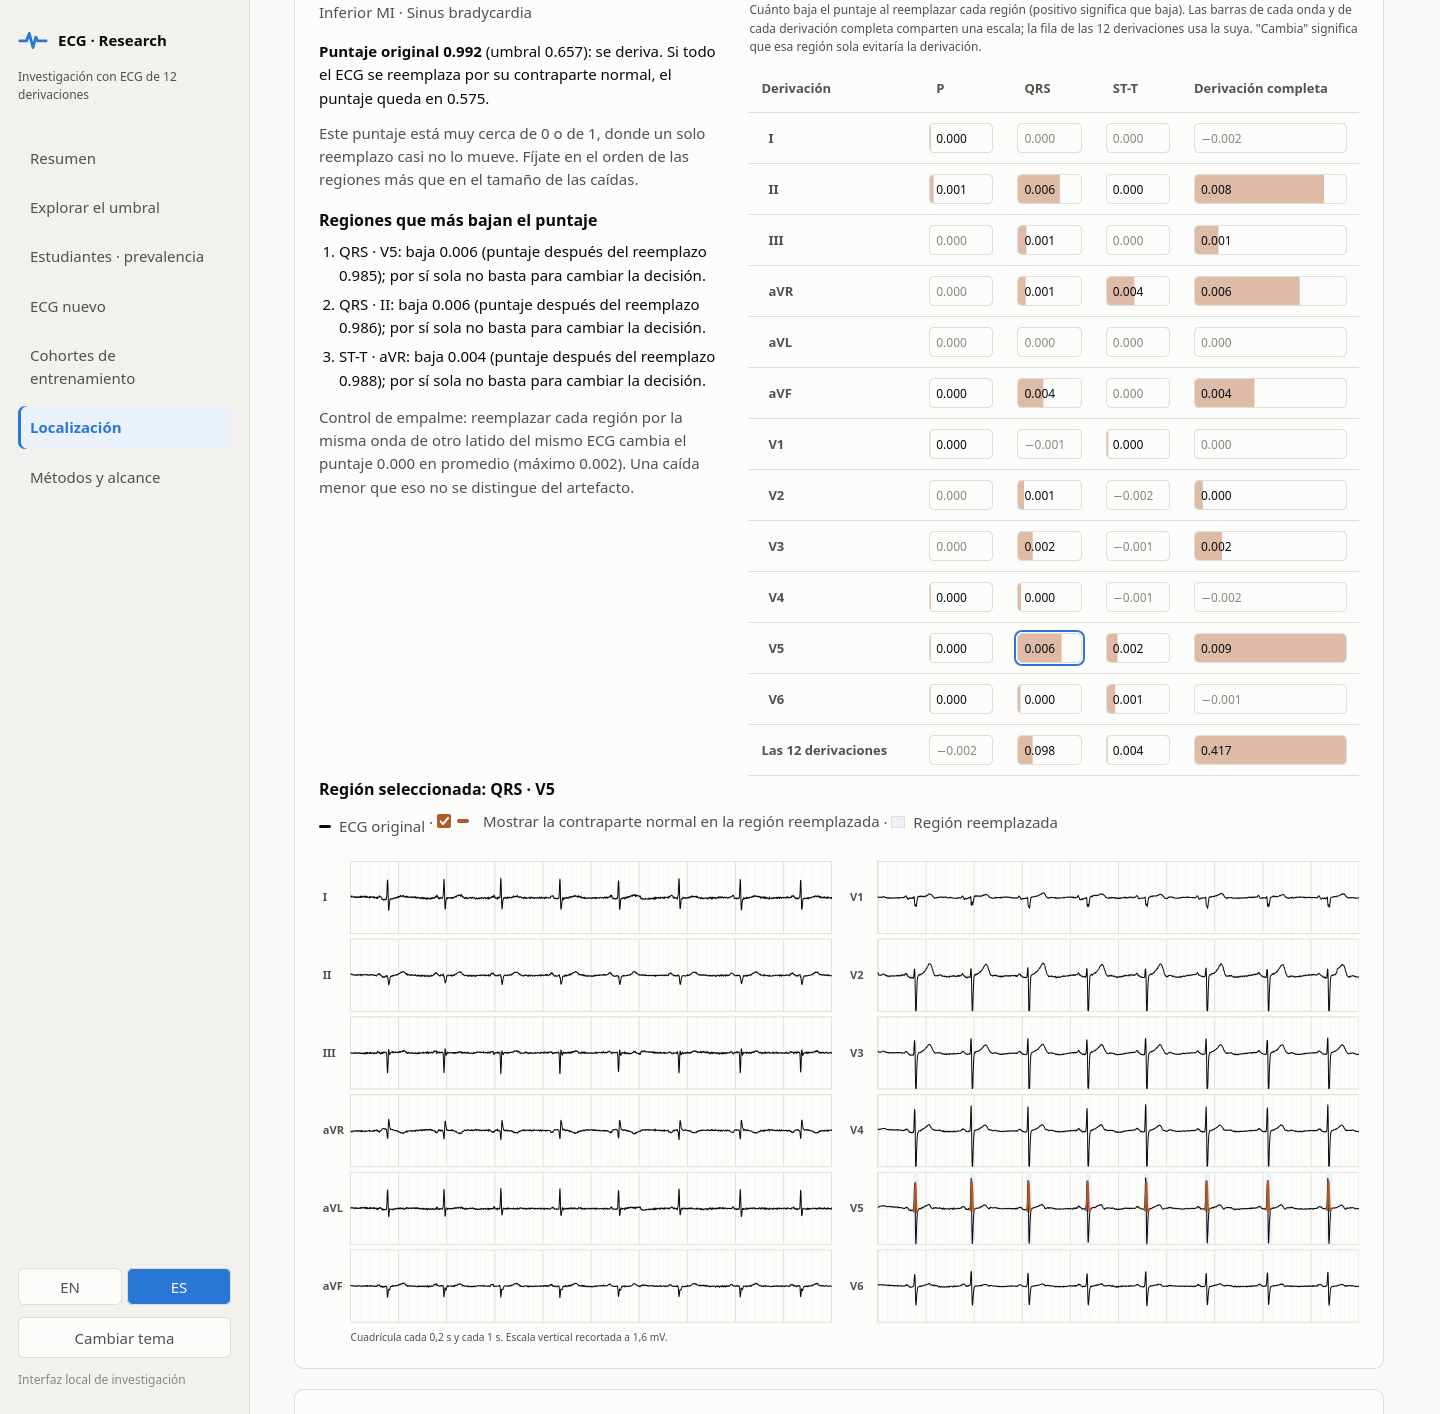

In [12]:
display(Image(filename=str(ROOT / "docs/figures/avance5-ui/localization.png"), width=1100))

,P,QRS,ST-T
I,0.000128,-0.000165,-0.000021
II,0.000515,0.006108,0.000003
III,-0.000160,0.001237,-0.000001
aVR,-0.000260,0.001120,0.003988
aVL,-0.000005,-0.000182,-0.000277
aVF,0.000006,0.003704,-0.000373
V1,0.000033,-0.000887,0.000171
V2,-0.000234,0.000877,-0.001866
V3,-0.000272,0.002151,-0.000966
V4,0.000133,0.000440,-0.000698


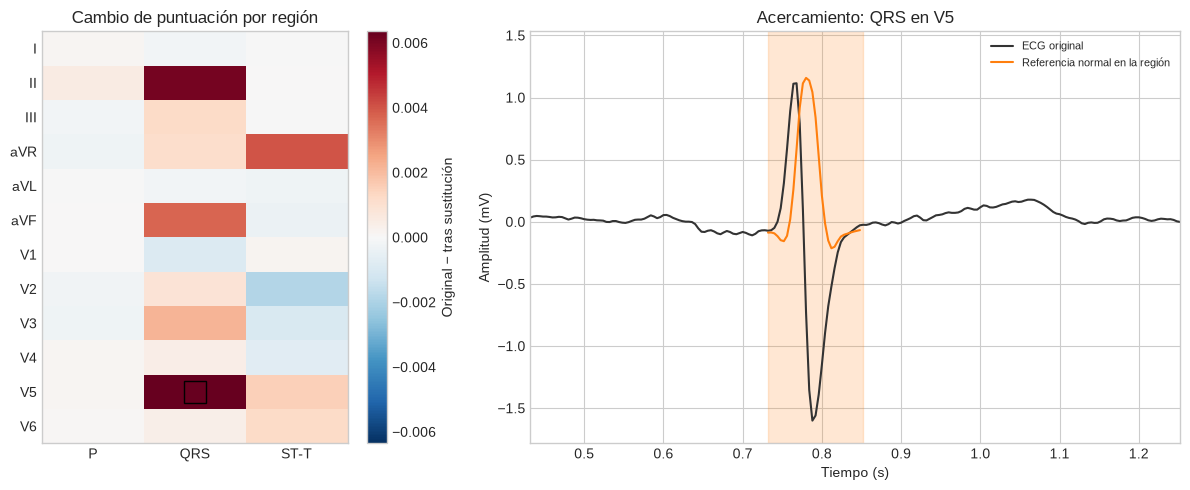

Región con mayor caída: QRS en V5. Original: 0.991625; tras sustitución: 0.985267; caída: 0.006358.
Umbral fijo: 0.656966. ¿Sigue marcada?: True.


En este ejemplo, la caída mayor corresponde al QRS en V5 y la alerta persiste. El acercamiento muestra un latido, pero la puntuación guardada refleja la sustitución de esa región en todos los latidos elegibles. El resaltado orienta sobre el modelo; no confirma una lesión en V5.

In [13]:
from ui.localization import load_localization
examples = load_localization(ROOT)
example = examples["examples"][0]
model_id = "all_age_blend"
scores = example["scores"][model_id]
original = float(scores["original"])
drops = original - np.asarray(scores["grid"], dtype=float)
leads, components = examples["leads"], examples["components"]
drop_table = pd.DataFrame(drops, index=leads, columns=components)
display(drop_table.round(6))
lead_index, component_index = np.unravel_index(np.argmax(drops), drops.shape)
lead, component = leads[lead_index], components[component_index]
after = float(scores["grid"][lead_index][component_index])
threshold = float(examples["models"][model_id]["threshold"])
windows = example["components"][component]
signal = np.asarray(example["signal"], dtype=float)
counterpart = np.asarray(example["counterpart"], dtype=float)
fs = float(examples["fs"])
times = np.arange(signal.shape[1]) / fs
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.7]})
limit = max(float(np.abs(drops).max()), 1e-9)
heatmap = axes[0].imshow(drops, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axes[0].set(xticks=range(len(components)), xticklabels=components,
            yticks=range(len(leads)), yticklabels=leads, title="Cambio de puntuación por región")
axes[0].grid(False)
axes[0].plot(component_index, lead_index, "ks", markersize=16, fillstyle="none")
fig.colorbar(heatmap, ax=axes[0], label="Original − tras sustitución")
axes[1].plot(times, signal[lead_index], color="0.2", label="ECG original")
reference = np.full_like(times, np.nan)
for start, stop in windows:
    reference[start:stop] = counterpart[lead_index, start:stop]
    axes[1].axvspan(start / fs, stop / fs, color="C1", alpha=0.18)
axes[1].plot(times, reference, color="C1", label="Referencia normal en la región")
start, stop = windows[0]
axes[1].set(xlim=(max(0, start / fs - 0.3), stop / fs + 0.4), xlabel="Tiempo (s)",
            ylabel="Amplitud (mV)", title=f"Acercamiento: {component} en {lead}")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(a5.REPORT / "05_localizacion_ejemplo.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Región con mayor caída: {component} en {lead}. Original: {original:.6f}; "
      f"tras sustitución: {after:.6f}; caída: {original - after:.6f}.")
print(f"Umbral fijo: {threshold:.6f}. ¿Sigue marcada?: {after > threshold}.")
display(Markdown("En este ejemplo, la caída mayor corresponde al QRS en V5 y la alerta persiste. "
    "El acercamiento muestra un latido, pero la puntuación guardada refleja la sustitución "
    "de esa región en todos los latidos elegibles. El resaltado orienta sobre el modelo; "
    "no confirma una lesión en V5."))

## 10. Prototipo y siguiente paso

Revisamos la aplicación en `ui/`: compara cohorts, muestra matrices exactas, explora umbrales,
calcula escenarios de prevalencia y presenta ejemplos de sustitución por referencia normal.
Si la calidad de un ECG nuevo falla, se abstiene y pide revisión; una abstención no es un negativo.
Su ejecución local se documenta en [ui/README.md](../ui/README.md). La captura del apartado de umbrales muestra
el prototipo local, cuya utilidad clínica todavía requiere evaluación.

La entrega integra discriminación, carga de revisión y explicación del modelo. El ensayo posterior de fine-tuning ya se ejecutó y se documenta a continuación. La validación clínica local sigue siendo necesaria.

In [14]:
print(f"Ejecución completa: {(time.perf_counter() - START) / 60:.1f} minutos")
display(pd.DataFrame([{"archivo": path.name, "kilobytes": round(path.stat().st_size / 1024, 1)}
    for path in sorted(a5.REPORT.iterdir()) if path.is_file()]))

Ejecución completa: 0.5 minutos


,archivo,kilobytes
0,01_roc.png,64.8
1,02_precision_recall.png,50.9
2,03_matriz_confusion.png,31.2
3,04_umbrales.png,53.3
4,05_localizacion_ejemplo.png,101.5
5,comparativa.csv,4.5
6,hiperparametros.csv,1.0
7,intervalo_vs_xecg.json,0.2
8,modelos_preentrenados.csv,0.7
9,presupuestos_derivacion.csv,1.1


## 10b. Ensayo adicional: fine-tuning completo de xECG

La mezcla con xECG ajustado obtuvo 76.2% de sensibilidad y
94.8% de especificidad en SPH, con AUROC 0.9367.
Frente a la mezcla congelada, detectó 43 ECG positivos menos y
generó 20 falsos positivos más.

Entrenamos todos los parámetros del backbone y la cabeza durante una pasada por los 25,000 ECG,
con tasa de aprendizaje fijada antes de evaluar.
Usamos BF16 (Brain Floating Point de 16 bits; formato numérico de precisión reducida)
para el entrenamiento y FP32 (Floating Point de 32 bits; formato de coma flotante de precisión
simple) para la evaluación. El tiempo de entrenamiento fue de 9.8 minutos.
No elegimos épocas ni tasa de aprendizaje con SPH o el pliegue 9; los controles y los normales
de calibración son los mismos que en la entrega inicial.

La diferencia de sensibilidad fue -1.20 puntos porcentuales,
IC 95% [-1.84, -0.59], con 2,000
remuestreos de pacientes. No superó el criterio práctico de mejora; conservamos el ensamble inicial como referencia. El criterio pedía al menos dos puntos de sensibilidad,
límite inferior positivo y como máximo 0.5 puntos adicionales de falsos positivos.

Una pasada y una semilla no agotan el fine-tuning posible. Este resultado mide anotaciones
hospitalarias en desarrollo reutilizado; todavía no acredita utilidad clínica en estudiantes.
[Protocolo y precisión numérica](../docs/avance5-finetune-v2-protocol-2026-10-29.md).

,model,ajuste,auroc,sensitivity,specificity,tp,fn,fp,tn
9,blend,Congelado,0.9374,0.7740,0.9507,2774,810,338,6512
3,blend,Fine-tuning completo,0.9367,0.7620,0.9477,2731,853,358,6492
10,xecg,Congelado,0.9321,0.7609,0.9504,2727,857,340,6510
2,xecg,Fine-tuning completo,0.9319,0.7458,0.9476,2673,911,359,6491


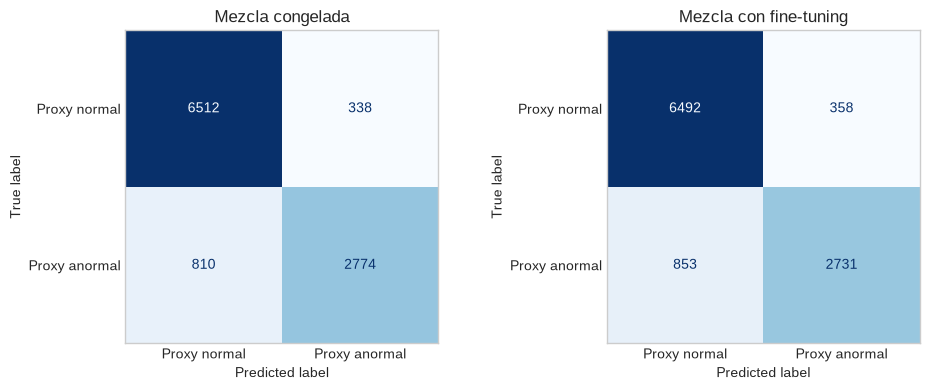

In [15]:
fine = a5.json_read(ROOT / "reports/avance5_finetune_v2/results.json")
fine_table = pd.DataFrame(fine["records"])
baseline = run["table"].query("sitio == 'sph' and id in ['xecg', 'blend']").copy()
baseline = baseline.rename(columns={"id": "model", "sitio": "site"})
baseline["ajuste"] = "Congelado"
updated = fine_table.query("site == 'sph'").copy()
updated["ajuste"] = "Fine-tuning completo"
display(pd.concat([baseline, updated])[["model", "ajuste", "auroc", "sensitivity",
    "specificity", "tp", "fn", "fp", "tn"]].sort_values(["model", "ajuste"]).round(4))
updated_blend = updated.query("model == 'blend'").iloc[0]
frozen_blend = baseline.query("model == 'blend'").iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
from sklearn.metrics import ConfusionMatrixDisplay
for ax, label, row in zip(axes, ("Mezcla congelada", "Mezcla con fine-tuning"),
                          (frozen_blend, updated_blend)):
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=int)
    ConfusionMatrixDisplay(matrix, display_labels=["Proxy normal", "Proxy anormal"]).plot(
        ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.grid(False)
    ax.set_title(label)
fig.tight_layout()
fig.savefig(ROOT / "reports/avance5_finetune_v2/matrices_comparadas.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Referencias

En los títulos aparecen FMs (Foundation Models; modelos fundacionales) y
AHA (American Heart Association; Asociación Estadounidense del Corazón).

- Kim, S. (2024, versión revisada 2026). *Learning General Representation of 12-Lead
  Electrocardiogram with a Joint-Embedding Predictive Architecture*.
  [arXiv:2410.08559](https://arxiv.org/abs/2410.08559).
- Al-Masud, M. A., Lopez Alcaraz, J. M. y Strodthoff, N. (2026). *Benchmarking ECG FMs:
  A Reality Check Across Clinical Tasks*. ICLR (International Conference on Learning Representations;
  Conferencia Internacional sobre Aprendizaje de Representaciones).
  [arXiv:2509.25095](https://arxiv.org/abs/2509.25095).
- Lunelli, R., Nicolson, A., Pröll, S. M., Reinstadler, S. J., Bauer, A. y Dlaska, C. (2026).
  *BenchECG and xECG: a benchmark and baseline for ECG foundation models*. npj Digital Medicine.
  [doi:10.1038/s41746-026-03196-y](https://doi.org/10.1038/s41746-026-03196-y).
- Drezner, J. A., et al. (2016). *Electrocardiographic Screening in National Collegiate Athletic
  Association Athletes*. American Journal of Cardiology, 118, 754–759.
  [doi:10.1016/j.amjcard.2016.06.004](https://doi.org/10.1016/j.amjcard.2016.06.004).
- Williams, E. A., et al. (2019). *Performance of the AHA 14-Point Evaluation Versus
  Electrocardiography for the Cardiovascular Screening of High School Athletes*.
  Journal of the American Heart Association, 8, e012235.
  [doi:10.1161/JAHA.119.012235](https://doi.org/10.1161/JAHA.119.012235).

## 12. Declaración de uso de IA (inteligencia artificial) y contribución del equipo

### Uso de herramientas de IA

Se utilizó una combinación de OpenAI Codex y Anthropic Claude durante el proyecto.
En particular, se pidió a Codex ejecutar diversos experimentos de forma autónoma durante la jornada,
además de apoyar la programación, la búsqueda de fuentes, la revisión de datos y la redacción.
El apoyo incluyó ejecutar código, leer los resultados, comprobarlos y documentar tanto los
avances como los intentos que no mejoraron el modelo.

También conversamos con nuestro tutor y recibimos orientación para el desarrollo del proyecto.
Esa asesoría acompañó la revisión del enfoque y las decisiones metodológicas. Las propuestas
de las herramientas se consideraron junto con esa orientación y la evidencia de los experimentos;
la responsabilidad de las decisiones y de su justificación corresponde al equipo.

Esta forma de trabajo nos llevó a crear una cola de tareas para ordenar las propuestas,
priorizar su utilidad y ejecutarlas en secuencia según los recursos disponibles. Antes de
iniciar una corrida costosa, medimos su tiempo y memoria. Así aprovechamos mejor nuestros
recursos limitados: por ejemplo, la primera propuesta de ajuste completo se detuvo por su
costo estimado y dio lugar al ensayo más acotado con precisión mixta.
[Cola y registro de experimentos](../docs/experiment-queue.md).

También usamos IA para crear una página con la que presentar el trabajo al equipo de Italia.
La mayor parte de la interfaz visible y de su lógica se desarrolló con apoyo de IA. La página
organiza la información de forma más sencilla e incorpora controles interactivos para explorar
los resultados, los umbrales y las regiones que influyen en la puntuación. Buscamos facilitar
la revisión del equipo y que el médico pueda interactuar con estas herramientas mediante una
interfaz más accesible. Esa facilidad de uso es un objetivo del prototipo y deberá comprobarse
con sus usuarios.

Experimentos y comprobaciones ejecutados para esta entrega:

- Comparación de los codificadores publicados JEPA, CPC y xECG con un clasificador final común.
- Entrenamiento de regresión logística, SVM y MLP sobre medidas físicas, y de xECG con regresión logística.
- Construcción de cinco ensambles: bosque aleatorio, boosting por histogramas, voto SVM/MLP,
  stacking SVM/MLP y mezcla de boosting con xECG.
- Búsqueda de hiperparámetros del bosque, del boosting y del clasificador final de xECG,
  usando únicamente las particiones de entrenamiento.
- Evaluación en los dos conjuntos de desarrollo, calibración con normales, comparación de
  presupuestos de falsas alertas y cálculo de intervalos por remuestreo de pacientes.
- Proyección de cargas hipotéticas de revisión con prevalencias publicadas, bajo supuestos explícitos.
- Perfil de recursos del ajuste completo en precisión de 32 bits; la corrida extensa no se lanzó
  porque no pasó el límite de costo.
- Perfil de precisión mixta, preparación verificada de las 25,000 señales, una pasada de ajuste
  completo de xECG y comparación de sus matrices con las del modelo congelado.
- Verificación independiente de matrices, métricas, particiones, archivos y ejecución de la libreta.

También se revisaron los resultados ya existentes de selección por edad, sustitución por
referencia normal y SHAP; esta entrega no volvió a ejecutar esos estudios completos.

La revisión exhaustiva de datos resultó especialmente útil para identificar problemas que el
equipo no había advertido. Las auditorías documentaron señales con derivaciones constantes,
registros duplicados y diferencias en duración, unidades y evidencia de las etiquetas.
También se detectaron cuestiones que requieren conocimiento médico: una interpretación
automática no equivale a una lectura validada por un especialista, y un voltaje alto aislado
puede ser fisiológico en atletas aunque una etiqueta general lo trate como anormal.
Esto motivó controles de calidad y una interpretación más cuidadosa del objetivo del modelo.
[Auditoría de datos](../docs/data-quality-assessment.md) y
[revisión de criterios clínicos](../docs/cardiologist-meeting-prep.md).

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Uso combinado de OpenAI. (2026). Codex [Agente de programación asistido por IA].<br>https://openai.com/codex/<br>Anthropic. (2026). Claude [Asistente de IA generativa].<br>https://claude.ai/ | Apoyo en código, revisión de datos, fuentes y redacción; organización de la cola; desarrollo de la mayor parte de la interfaz y lógica de la página. A Codex se le encargó además ejecutar y documentar los experimentos enumerados. | Secciones 1–10b, referencias y prototipo interactivo. | El equipo aporta el objetivo, los criterios de interpretación y la orientación recibida del tutor. Se ejecutaron controles automáticos de particiones, archivos, métricas y matrices. Corresponde al equipo revisar la entrega y contrastar las observaciones médicas con especialistas. |

### Contribución individual

Las áreas de Clara y José retoman la distribución del avance anterior. Se incorpora la
creación de la página por Andre, confirmada por el equipo para esta entrega.

| Integrante | Responsabilidades y contribución al avance |
|---|---|
| Clara Janet Rivera Medina | Arquitectura, representación del ECG y métricas. |
| José Emiliano Luna López | Evaluación comparativa y elección del modelo. |
| Andre Nicolai Gutierrez Bautista | Creó la página para presentar el proyecto al equipo de Italia, incluyendo su interfaz y lógica, con apoyo de IA. Su área de trabajo también comprende hiperparámetros y ensambles. |

### Decisiones principales

<small>Decisión 1: Mantener el cohort general de 25,000 ECG sin preferencia por edad.</small>

- <small>Justificación: conserva mayor diversidad de edades. La comparación estricta de jóvenes
  no alcanzó la mejora mínima predefinida; la selección de 25,000 que priorizaba jóvenes seguía
  siendo mayoritariamente adulta.</small>
- <small>Alternativa descartada y motivo: limitar el entrenamiento a los 770 ECG de 18–25 años,
  porque reduciría considerablemente los datos sin una ventaja concluyente en el estudio.</small>

<small>Decisión 2: Conservar la mezcla de boosting y xECG congelado como modelo elegido.</small>

- <small>Justificación: fue la mejor receta según la selección con entrenamiento y alcanzó
  77.4% de sensibilidad y 95.1% de especificidad en SPH.</small>
- <small>Alternativa descartada y motivo: sustituirla por la mezcla con ajuste completo de xECG.
  La receta ensayada detectó 43 positivos menos y produjo 20 falsos positivos más en SPH.
  Documentamos ese resultado y conservamos el modelo con mejor punto de operación.</small>

<small>Decisión 3: Fijar el umbral con normales de calibración y mostrar su efecto en la carga de revisión.</small>

- <small>Justificación: el presupuesto de falsas alertas permite relacionar el modelo con la
  capacidad del servicio. La página facilita explorar cómo cambian la sensibilidad y los conteos.</small>
- <small>Alternativa descartada y motivo: usar un umbral universal, por ejemplo 0.5, o elegirlo
  mirando los resultados de evaluación. Las puntuaciones no son probabilidades clínicas calibradas
  y un mismo corte no asegura la misma carga entre hospitales.</small>

### Decisiones complementarias y sus implicaciones

4. Usar anotaciones con evidencia de revisión humana y conservar controles de calidad.
   Justificación: duplicados, derivaciones constantes o etiquetas automáticas pueden distorsionar
   la evaluación. Alternativa descartada: incorporar todos los registros disponibles solo para
   aumentar el tamaño. Implicación: una selección más confiable, aunque no elimine todos los errores.

5. Comparar JEPA, CPC y xECG con la misma tarea y el mismo clasificador final.
   Justificación: facilita interpretar sus diferencias en nuestros datos. Alternativa descartada:
   elegir únicamente por las métricas publicadas en papers con otras etiquetas y poblaciones.
   Implicación: xECG fue el mejor de esos tres en esta comparación, sin establecer superioridad universal.

6. Reservar entrenamiento para elegir hiperparámetros y calibración para fijar el umbral.
   Justificación: cada paciente conocido queda dentro de su partición y se evita ajustar decisiones
   a los resultados que se quieren evaluar. Alternativa descartada: elegir configuraciones con
   las etiquetas del hospital de evaluación. Implicación: los datos reutilizados se describen como
   desarrollo y los conjuntos reservados permanecen fuera de los nuevos experimentos.

7. Organizar el trabajo en una cola y medir los recursos antes de entrenar.
   Justificación: permite priorizar experimentos y ejecutar las tareas dentro de nuestra capacidad.
   Alternativa descartada: lanzar todas las propuestas completas sin medir tiempo y memoria.
   Implicación: se evitó la corrida extensa en precisión completa y se ejecutó un ensayo acotado
   de ajuste de todos los parámetros con precisión mixta; su resultado negativo también se conservó.

8. Usar sustitución por referencia normal para explicar qué regiones influyen en el modelo.
   Justificación: conecta un cambio visible del ECG con un cambio medible de puntuación, y admite
   controles de energía y de intercambio entre latidos. Alternativa descartada: presentar un mapa
   visual o una atribución de variables como localización clínica confirmada. Implicación: la página
   orienta la revisión, pero necesita etiquetas de especialistas para validar las regiones señaladas.

9. Crear una página interactiva como apoyo para presentar los resultados al equipo de Italia.
   Justificación: permite revisar señales, conteos, umbrales y regiones sin recorrer todo el código.
   Alternativa descartada: depender únicamente de tablas estáticas y de la libreta para esa presentación.
   Implicación: Andre desarrolló la página con apoyo de IA; su facilidad de uso debe evaluarse con
   el equipo y el médico antes de asumir que mejora el trabajo clínico.

10. Tratar las proyecciones como escenarios condicionados a supuestos.
    Justificación: los estudios estadounidenses y nuestros datos hospitalarios no representan
    directamente a los estudiantes italianos. Alternativa descartada: presentar los conteos calculados
    como diagnósticos o resultados esperados ya validados en Italia. Implicación: las proyecciones
    ayudan a discutir carga de revisión y necesidades de datos, sin sustituir una validación local.